## Diffusive Equation Interpretation with Multi-Relaxation Time (MRT-Framework)

The multiple-relaxation-time (MRT) collision model is a well-established scheme in the LBM literature that allows different non-equilibrium moments to relax independently. This flexibility enables various improvements in the numerical representation of partial differential equations. In the present section, we extend the FDM interpretation to the MRT framework of diffusive equation, following the analysis presented by {cite:t}`lin2021multiple`.


Given the LB equation with MRT for the diffusive equation:

$$
f_i( x_{\alpha} + e_{i,\alpha} \delta t, t+\delta t) = f_i(x_{\alpha}, t)  - (\textbf{M}^{-1}\textbf{S}\textbf{M})_{ik}\left( f_{k} - f_{k}^{eq}  \right), 
$$(MRT-LB-fdm-diff-Eq)

where $\textbf{M}$ is matrix of moments, $\textbf{S}$ is the diagonal matrix of relaxation times, and $\textbf{M}^{-1}$ is the inverse matrix of $\textbf{M}$. Considering the problem description in a lattice D1Q3, we have following a Gram-Schmidt procedure:

$$
\textbf{M} =\begin{pmatrix} 1 \\ e_{i,x} \\ 3e_{i,x}^{2}-2 \end{pmatrix} =\begin{pmatrix} 1 & 1 & 1 \\ 0 & 1   & -1 \\ -2  & 1 & 1 \end{pmatrix},  \qquad \qquad  \textbf{S} = \begin{pmatrix} 0 & 0   & 0 \\ 0   & s_1 & 0 \\ 0   & 0   & s_2 \end{pmatrix},  \qquad \qquad \textbf{M}^{-1}=\begin{pmatrix}\dfrac{1}{3} & 0 & -\dfrac{1}{3} \\ \dfrac{1}{3} & \dfrac{1}{2} & \dfrac{1}{6} \\ \dfrac{1}{3} & -\dfrac{1}{2} & \dfrac{1}{6} \end{pmatrix}.
$$

In [34]:
import warnings
warnings.filterwarnings("ignore")
import sympy as sp
import numpy as np
from IPython.display import display, Math, Markdown
sp.init_printing()
# =========================Symbols=============================================
f0, f1, f2 = sp.symbols(r'f_{0\,x}^{t} f_{1\,x}^{t} f_{2\,x}^{t}' ) # Distribution functions at x,t
f0m, f1m, f2m = sp.symbols(r'f_{0\,x-1}^{t} f_{1\,x-1}^{t} f_{2\,x-1}^{t}' ) # Distribution functions at neighboring nodes
f0p, f1p, f2p = sp.symbols(r'f_{0\,x+1}^{t} f_{1\,x+1}^{t} f_{2\,x+1}^{t}')
f0t1, f0m1t1, f1m1t1, f2m1t1, f0p1t1, f1p1t1, f2p1t1 = sp.symbols(['f_{0\,x}^{t-1}','f_{0\,x-1}^{t-1}','f_{1\,x-1}^{t-1}','f_{2\,x-1}^{t-1}','f_{0\,x+1}^{t-1}','f_{1\,x+1}^{t-1}','f_{2\,x+1}^{t-1}'])
f0_new, f1_new, f2_new = sp.symbols(r'f_{0\,x}^{t+1} f_{1\,x}^{t+1} f_{2\,x}^{t+1}') # Distribution functions after one time step
phi, phi_m, phi_p = sp.symbols(r'\phi_x^t \phi_{x-1}^t \phi_{x+1}^t') # Macroscopic field
phitp1, phit1, phit2= sp.symbols(['\\phi_{x}^{t+1}','\\phi_{x}^{t-1}','\\phi_{x}^{t-2}'])
phim1t1,phip1t1= sp.symbols(['\\phi_{x-1}^{t-1}','\\phi_{x+1}^{t-1}'])
s0,s1, s2 = sp.symbols('s_0 s_1 s_2') # MRT relaxation parameters
# D1Q3 weights:
w0 = sp.symbols('w_0')
w1 = (1 - w0) / 2
# ==========================D1Q3 lattice=======================================
w0 = sp.symbols('w_0')
w1 = (1 - w0) / 2
cxM = sp.Matrix([0,1,-1])
cx=np.array([0,1,-1])
w = sp.Matrix([w0,w1,w1])
# ===========================Distribution vector===============================
f = sp.Matrix([f0,f1,f2])
f_new = sp.Matrix([f0_new,f1_new,f2_new])
# =====================Moment transformation matrix============================
m0=np.array([1,1,1])
m1=cx
m2=3*cx*cx - 2
# m2=cx*cx - sp.Rational(1,3)
M=sp.Matrix([m0,m1,m2])
Minv = sp.simplify(M.inv())
# =============================Relaxation matrix===============================
S = sp.diag(0,s1,s2)
# ==============Equilibrium distribution and equilibrium moments===============
feq = sp.simplify(phi * w)
meq = sp.simplify(M * feq)

Applying the same shift scheme employed in Eq. {eq}`pre-fdm-LB-df-Eq` to Eq. {eq}`MRT-LB-fdm-diff-Eq`, we obtain

In [35]:
def brokeq(equation, terms_per_line=4):
    lhs = sp.latex(equation.lhs)
    rhs_terms = list(sp.Add.make_args(equation.rhs))

    lines = []
    for i in range(0, len(rhs_terms), terms_per_line):
        group = rhs_terms[i:i + terms_per_line]

        # Build the latex for this group manually so we control signs
        terms_latex = []
        for j, term in enumerate(group):
            coeff, rest = term.as_coeff_Mul()
            sign = "-" if coeff < 0 else "+"
            # strip sign from latex
            term_latex = sp.latex(abs(coeff) * rest) if coeff != 1 and coeff != -1 \
                         else sp.latex(rest)
            terms_latex.append((sign, term_latex))

        # First term of the whole RHS has no leading + / -
        first_sign, first_tex = terms_latex[0]
        if i == 0:
            head = first_tex if first_sign == "+" else f"- {first_tex}"
            line = rf"{lhs} &= {head}"
        else:
            head = first_tex if first_sign == "+" else f"- {first_tex}"
            prefix = "+ " if first_sign == "+" else ""
            # Actually for continuation we want the sign explicit:
            line = rf"&\quad {first_sign} {first_tex}"

        # Remaining terms in the group
        for sign, tex in terms_latex[1:]:
            line += rf" {sign} {tex}"

        lines.append(line)

    return r"\begin{aligned}" + r" \\ ".join(lines) + r"\end{aligned}"

In [36]:
# ==========================MRT collision operator=============================
f_post = sp.simplify(f - Minv * S * M * (f - feq))
# ==========================Streaming==========================================
fp0 = sp.simplify(f_post[0])  # Rest population
fp1 = sp.simplify(f_post[1].subs({f0: f0m, f1: f1m, f2: f2m, phi: phi_m }).subs(f1 + f2, phi - f0) )
fp2 = sp.simplify(f_post[2].subs({f0: f0p, f1: f1p, f2: f2p, phi: phi_p}).subs(f1p + f2p, phi_p - f0p) )
# =============================Final lattice equations=========================
f_post2 = sp.Matrix([fp0,fp1,fp2])
display(Math(sp.latex(sp.Eq(f_new,f_post2)) + r','))

<IPython.core.display.Math object>

In [37]:
display(sum(feq*m2))

array([-2*\phi_x^t*w_0 - 2*\phi_x^t*(1 - w_0),
       \phi_x^t*w_0 + \phi_x^t*(1 - w_0),
       \phi_x^t*w_0 + \phi_x^t*(1 - w_0)], dtype=object)

In [38]:
meq[2]

In [39]:
feqs=Minv*S*M*(feq)

In [40]:
display(sp.simplify(sum(feqs) ))
display(sp.simplify(sum(feqs*m1))) 

In [41]:
feqs.T*cxM*cxM.T

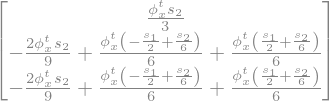

In [42]:
( Minv * S * M * (feq) ).subs(w0,sp.Rational(2,3))

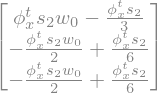

In [43]:
 sp.expand(Minv * S * M * (feq))

expanding each term and replacing the conservative terms:

In [44]:
# fp0=sp.collect(sp.expand(f_post2[0].subs(f1,phi-f0-f2)),{f0,phi})
fp0=sp.collect(sp.expand(f_post2[0]),{f0,phi})
display(Math(sp.latex(sp.Eq(f0_new,fp0)) + r','))

<IPython.core.display.Math object>

In [45]:
fp0=sp.collect(sp.expand(f_post2[0].subs(f1,phi-f0-f2)),{f0,phi})
display(Math(sp.latex(sp.Eq(f0_new,fp0)) + r','))

<IPython.core.display.Math object>

In [46]:
# eq1=sp.collect(sp.expand(f_post2[1]),{s1,phi_m,-s2/6}).subs(f1m+f2m,phi_m-f0m)
fp1=sp.collect(sp.expand(sp.collect(f_post2[1],{s1,phi_m,-s2/6}).subs(f1m+f2m,phi_m-f0m)),{s1/2})
display(Math(sp.latex(sp.Eq(f1_new,fp1)) + r','))

<IPython.core.display.Math object>

In [47]:
fp2=sp.collect(sp.expand(sp.collect(f_post2[2],{s1,phi_p,-s2/6}).subs(f1p+f2p,phi_p-f0p)),{s1/2})
display(Math(sp.latex(sp.Eq(f2_new,fp2)) + r'.'))

<IPython.core.display.Math object>

Summing over all lattice direction, we have:

In [48]:
term1=sp.collect(fp0+fp1+fp2,[w0*s2,s2,s1/2])
latex_str = brokeq(sp.Eq(phi_p, term1), terms_per_line=4)
display(Math(latex_str + r','))

<IPython.core.display.Math object>

Using the shift interpretation for the distribution functions, we obtain

$$
f_{0,x}^{t}+f_{1,x+1}^{t}+f_{2,x-1}^{t}=\phi^{t-1}_{x},
$$(rel-f-1)

applying this relation to the equation above:

In [60]:
term2=sp.collect(fp0+fp1+fp2,[w0*s2,s2,s1/2]).subs(f1p,phit1-f0-f2m).subs(f1p,phit1-f0-f2m)
latex_str = brokeq(sp.Eq(phi_p,term2), terms_per_line=4)
display(Math(latex_str + r'.'))

<IPython.core.display.Math object>

To repalce the term $f_{0,x}^{t}+f_{1,x-1}^{t}+f_{2,x+1}^{t}$, in the above equation we use the $\sum_{i}f_{i,x}^{t}=\phi_{x}^{t}$:

In [61]:
rel2=(f0+f1m+f2p).subs(f1m,phi_m-f0m-f2m).subs(f2p,phi_p-f0p-f1p).subs(-f1p-f2m,f0-phit1)
display(Math(sp.latex(sp.Eq(f0+f1m+f2p,rel2)) + r','))

<IPython.core.display.Math object>

where

In [62]:
term3=sp.collect(fp0+fp1+fp2,[w0*s2,s2,s1/2]).subs(f1p,phit1-f0-f2m).subs(f1p,phit1-f0-f2m).subs(f1m+f2p,rel2-f0)
term4=sp.collect(sp.collect(sp.expand(term3),[f0m,f0,f0p,phi_p,phi_m,phit1]).subs(f0*(-s1-s2+2),-2*f0*(s1/2+s2/2-1)),(s1/2+s2/2-1))
display(Math(sp.latex(sp.Eq(phi_p,term4)) + r'.'))

<IPython.core.display.Math object>

$$
\begin{array}{ll}
\phi_{x+1}^t & = \phi^{t}_{x} s_{2} w_{0} + \phi_{x+1}^t \left(- \displaystyle\frac{s_{1}}{2} - \frac{s_{2} w_{0}}{2} + 1\right) + \phi_{x-1}^t \left(- \displaystyle\frac{s_{1}}{2} - \frac{s_{2} w_{0}}{2} + 1\right) + \phi_{x}^{t-1} \left(s_{1} - 1\right) \\
& + \left(f_{0,x+1}^{t} + f_{0,x-1}^{t} - 2 f_{0,x}^{t}\right) \left(\displaystyle\frac{s_{1}}{2} + \frac{s_{2}}{2} - 1\right)
\end{array}
$$(rel-pre-shift-2)

To replace the distribution function in the above relation, we manipulate:

In [63]:
rel3=(-2*f0+f0m+f0p).subs(-2*f0,-2*phi + 2*f1+ 2*f2)
display(Math(sp.latex(sp.Eq(-2*f0+f0m+f0p,rel3)) + r','))

rel3s1=sp.collect(rel3.subs(f0p,phip1t1*s2*w0-f0p1t1*s2+f0p1t1).subs(f0m,phim1t1*s2*w0-f0m1t1*s2+f0m1t1).subs(f1,-phim1t1*s2*w0/2+f0m1t1*s2/2+f1m1t1+s1/2*(f2m1t1-f1m1t1)) 
       .subs(f2,-phip1t1*s2*w0/2+f0p1t1*s2/2+f2p1t1+s1/2*(f1p1t1-f2p1t1)),s1)
display(Math(sp.latex(sp.Eq(-2*f0+f0m+f0p,rel3s1)) + r','))

rel3s2=(rel3s1.subs(f1m1t1,phim1t1-f0m1t1-f2m1t1).subs(f2p1t1,phip1t1-f0p1t1-f1p1t1))
latex_str = brokeq(sp.Eq(-2*f0+f0m+f0p,rel3s2), terms_per_line=7)
display(Math(latex_str + r','))

rel3s3=sp.collect(sp.simplify(sp.collect(sp.expand(rel3s2.subs(f2m1t1,phit2-f0t1-f1p1t1)),[f0p1t1,f0m1t1,2*f0t1,phim1t1,phip1t1,phit2])),[s1-1])
display(Math(sp.latex(sp.Eq(-2*f0+f0m+f0p,rel3s3)) + r'.'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Replacing the above relation in $\phi_{x}^{t+1}$ term:

In [66]:
term5=sp.simplify(sp.collect(sp.expand(term4.subs(-2*f0+f0m+f0p,rel3s3)),[phi_m,phi_p,phim1t1,phip1t1,phit1,phit2,phi,f0p1t1,f0m1t1,f0t1]))
term5s1=sp.collect(term5,[s1*s1+s1*s2-3*s1-s2+2,s1+w0*s2-2,s1*s1+s1*s2-4*s1-2*s2+4]).subs(s1*s1+s1*s2-3*s1-s2+2,(s1-1)*(s1+s2-2))
# display(Math(sp.latex(sp.Eq(phitp1,term5s1)) + r'.'))
latex_str = brokeq(sp.Eq(phitp1,term5s1), terms_per_line=3)
display(Math(latex_str + r'.'))

<IPython.core.display.Math object>

Applying a time shift in the Eq. {eq}`rel-pre-shift-2` to replace $f^{t-1}_{0,x+1}/2+f^{t-1}_{0,x-1}/2-f^{t-1}_{0,x}$ in the above equation, we obtain in the final form $\phi^{t+1}_{x}$ only dependent of previous moments:

In [72]:
term6=sp.simplify(sp.expand(term5s1.subs( -f0t1+f0m1t1/2+f0p1t1/2, (phi-(phip1t1+phim1t1)*(1-s1/2-s2*w0/2) - phit2*(s1-1) - phit1*s2*w0)/(s1+s2-2) ) ))
term6_2=sp.collect(term6,[phi_m,phi_p,phi,phim1t1,phip1t1,phit1,phit2])
# display(Math(sp.latex(sp.Eq(phitp1,term6_2)) + r'.'))
latex_str = brokeq(sp.Eq(phitp1,term6_2), terms_per_line=2)
display(Math(latex_str + r'.'))

<IPython.core.display.Math object>

### Fourth-order MRT Diffusive Equation

Following the same error analysis performed in the previous {ref}`section <Convergence Errors-mrt-diffusive-fourth-order>` for the single-relaxation-time model, we expand the relevant terms in Taylor series (Eq. {eq}`FDM-LBM-diff-expansions-phi`) and substitute them into the derived lattice Boltzmann equation to recover the corresponding partial differential equation, including truncation errors up to fourth order. The symbolic derivation leading to this equation is provided in the accompanying {doc}`SymPy code <appendix/sympy-code-mrt-fdm-diffusive-expansion-4th>`. Rearranging all terms on one side of the equation, we obtain:

$$
\begin{array}{ll}
0=&\displaystyle\frac{\Delta_{t}^{2} \left(- 3 s_{1} s_{2} + 2 s_{1} + 2 s_{2}\right)}{2} \frac{\partial^{2}\phi}{\partial t^{2}}  + \frac{\Delta_{t} \Delta_{x}^{2} \left(s_{1} s_{2} w_{0} - s_{1} s_{2} + s_{1} - s_{2} w_{0} + 2 s_{2} - 2\right)}{2} \frac{\partial^{3}\phi}{\partial x^{2}\partial t} \\
&+ \Delta_{t} s_{1} s_{2} \displaystyle\frac{\partial \phi}{\partial t} + \frac{\Delta_{x}^{4} s_{2} \left(- s_{1} w_{0} + s_{1} + 2 w_{0} - 2\right)}{24} \frac{\partial^{4}\phi}{\partial x^{4}} + \frac{\Delta_{x}^{2} s_{2} \left(- s_{1} w_{0} + s_{1} + 2 w_{0} - 2\right)}{2} \frac{\partial^{2}\phi}{\partial x^{2}}.
\end{array}
$$

Isolation the first order partial derivative term in left-had side of equation:

$$
\begin{array}{rl}
\Delta_{t} s_{1} s_{2} \displaystyle\frac{\partial \phi}{\partial t} &= - \displaystyle\frac{\Delta_{x}^{2} s_{2} \left(- s_{1} w_{0} + s_{1} + 2 w_{0} - 2\right)}{2} \frac{\partial^{2}\phi}{\partial x^{2}} -\frac{\Delta_{t}^{2} \left(- 3 s_{1} s_{2} + 2 s_{1} + 2 s_{2}\right)}{2} \frac{\partial^{2}\phi}{\partial t^{2}}  \\
&- \displaystyle\frac{\Delta_{t} \Delta_{x}^{2} \left(s_{1} s_{2} w_{0} - s_{1} s_{2} + s_{1} - s_{2} w_{0} + 2 s_{2} - 2\right)}{2} \frac{\partial^{3}\phi}{\partial x^{2}\partial t} - \frac{\Delta_{x}^{4} s_{2} \left(- s_{1} w_{0} + s_{1} + 2 w_{0} - 2\right)}{24} \frac{\partial^{4}\phi}{\partial x^{4}},\\
\displaystyle\frac{\partial \phi}{\partial t} &= \displaystyle\frac{\Delta_{x}^{2} (1-w_{0})\left(2 - s_{1}\right)}{2\Delta_{t} s_{1} } \frac{\partial^{2}\phi}{\partial x^{2}} - \frac{\Delta_{t} \left(- 3 s_{1} s_{2} + 2 s_{1} + 2 s_{2}\right)}{2 s_{1} s_{2}} \frac{\partial^{2}\phi}{\partial t^{2}}  \\
&- \displaystyle\frac{\Delta_{x}^{2} \left(s_{1} s_{2} w_{0} - s_{1} s_{2} + s_{1} - s_{2} w_{0} + 2 s_{2} - 2\right)}{2 s_{1} s_{2}} \frac{\partial^{3}\phi}{\partial x^{2}\partial t} + \frac{\Delta_{x}^{4} (1-w_{0})\left(2 - s_{1}\right)}{24\Delta_{t} s_{1}} \frac{\partial^{4}\phi}{\partial x^{4}}.
\end{array}
$$

Considering diffusive coeficient $\nu=(1-w_{0})\left(\frac{1}{s_{1}} - \frac{1}{2}\right)\frac{\Delta_{x}^{2}}{\Delta_{t}}$, we can rewrite the equation

$$
\frac{\partial \phi}{\partial t} = \nu\frac{\partial^{2}\phi}{\partial x^{2}} -\frac{\Delta_{t} \left(- 3 s_{1} s_{2} + 2 s_{1} + 2 s_{2}\right)}{2 s_{1} s_{2}} \frac{\partial^{2}\phi}{\partial t^{2}}  - \frac{ \Delta_{x}^{2} \left(s_{1} s_{2} w_{0} - s_{1} s_{2} + s_{1} - s_{2} w_{0} + 2 s_{2} - 2\right)}{2 s_{1} s_{2}} \frac{\partial^{3}\phi}{\partial x^{2}\partial t} + \frac{\nu\Delta_{x}^{2}}{12} \frac{\partial^{4}\phi}{\partial x^{4}}
$$

Using the relations:

$$
\frac{\partial\phi}{\partial t} = \nu \frac{\partial^{2}\phi}{\partial x^{2}}, \qquad \frac{\partial^{2}\phi}{\partial t^{2}} = \nu^{2} \frac{\partial^{4}\phi}{\partial x^{4}}, \qquad \frac{\partial^{3}\phi}{\partial x^{2}\partial t} = \nu \frac{\partial^{4}\phi}{\partial x^{4}},
$$

we can reduce the equation in terms of $\frac{\partial^{4}\phi}{\partial x^{4}}$:

$$
\begin{array}{rl}
\displaystyle\frac{\partial \phi}{\partial t} & = \nu \displaystyle\frac{\partial^{2}\phi}{\partial x^{2}} - \frac{\Delta_{x}^{2} (1-w_{0})\left(2 - s_{1}\right)}{2 s_{1} }\frac{\nu \left(- 3 s_{1} s_{2} + 2 s_{1} + 2 s_{2}\right)}{2 s_{1} s_{2}} \frac{\partial^{4}\phi}{\partial x^{4}}  \\
&- \displaystyle\frac{ \Delta_{x}^{2} \nu \left(s_{1} s_{2} w_{0} - s_{1} s_{2} + s_{1} - s_{2} w_{0} + 2 s_{2} - 2\right)}{2 s_{1} s_{2}} \frac{\partial^{4}\phi}{\partial x^{4}} + \frac{\nu\Delta_{x}^{2}}{12} \frac{\partial^{4}\phi}{\partial x^{4}}\\
\displaystyle\frac{\partial \phi}{\partial t} & = \nu \displaystyle\frac{\partial^{2}\phi}{\partial x^{2}} + \frac{\Delta_{x}^{2} \nu \left(3 s_{1}^{2} s_{2} w_{0} - 2 s_{1}^{2} s_{2} - 6 s_{1}^{2} w_{0} - 18 s_{1} s_{2} w_{0} + 12 s_{1} s_{2} + 12 s_{1} w_{0} + 12 s_{2} w_{0} - 12 s_{2}\right)}{12 s_{1}^{2} s_{2}} \frac{\partial^{4}\phi}{\partial x^{4}}
\end{array}
$$

Making the term $\left(3 s_{1}^{2} s_{2} w_{0} - 2 s_{1}^{2} s_{2} - 6 s_{1}^{2} w_{0} - 18 s_{1} s_{2} w_{0} + 12 s_{1} s_{2} + 12 s_{1} w_{0} + 12 s_{2} w_{0} - 12 s_{2}\right)$ equal to zero e can reach fourth order approximation. For $w_{0}=2/3$ (weight specific from the lattice D1Q3) the relation reduce to $4s_{1}^{2} -8s_{1}+4s_{2}$:

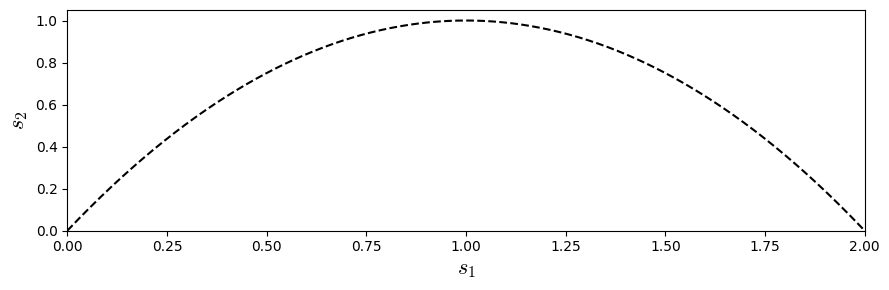

In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'cm'

# ---- data ----
s1r = np.linspace(0, 2.0, 1000)
s2r  = s1r*(2-s1r)
plt.figure(figsize=(9,3))
plt.plot(s1r,s2r,'k--')
plt.xlabel(r'$s_{1}$',fontsize=16)
plt.ylabel(r'$s_{2}$',fontsize=16)
plt.xlim(0,2)
plt.ylim(0,1.05)

plt.tight_layout()
plt.show()

In [5]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['mathtext.fontset'] = 'cm'
matplotlib.rcParams['mathtext.fontset'] = 'cm'
#--------------------------------------- Parameters (physical units) ------------------------------------------
A   = 1.0                         # Amplitude
phi = 0.0                         # Wave initial shift
k_w   = 1.0                       # Wave number
c   = 0.0                         # wave speed
nu  = 0.066666666666666666*np.pi # Diffusive coefficient
m_waves = 1                       # Wave Period
L = m_waves * (2.0*np.pi / k_w)   # Domain Lentgh
t_end = 12.0                       # Final time
#--------------------------------------- Lattice-Properties-D1Q3 ----------------------------------------------
w = np.array([4.0/6.0, 1.0/6.0, 1.0/6.0],dtype="float64")
cx = np.array([0, 1, -1],dtype="int16")  
cs=1.0/np.sqrt(3.0);
#--------------------------------- Initialization - Save Data Arrays -----------------------------------------------
cases=4
Nx0 = np.array([10, 20, 40, 80],dtype="int64")
r0 = 2**(0)*np.array([2.0**(1), 2.0**(2), 2.0**(3), 2.0**(4)],dtype="float64")
u_cases = np.empty(cases, dtype=object) # array field used to same data over time
for i in range(cases):
    u_cases[i] = np.zeros((Nx0[i]), dtype="float64")
for case in range(0,cases):
    #------------------------------------- Parameters (numerical units) -------------------------------------------
    Nx=Nx0[case]  # Numerical Length
    x  = np.linspace(0.0, L, Nx, endpoint=False,dtype="float64") # Numerical Domain
    dx = L / Nx # Grid size
    r = 1*r0[case] # dx/dt relation
    dt = dx/r
    ce = c/r
    nue = nu * dt / (dx*dx)
    tau1 = 0.5 + nue / cs**2
    tau2=1.0/((1.0/tau1)*(2.0-(1.0/tau1)))
    nt = int(np.ceil(t_end / dt))
    print(f"dx={dx:.4e},\t dt={dt:.4e}\t nt={nt:d},\t tn={nt*dt:.2f}") # Print values for check
    print(f"c_lbm={ce:.3f},\t tau1={tau1:.4f},\t tau2={tau2:.4f}")
    print(f"s1={1.0/tau1:.4f},\t s2={1.0/tau2:.4f}")
    print(f"nt={nt:.3f}\t, nue={nue:.4f}")
    #--------------------------------- Initialization - LBM - Numerical Arrays -----------------------------------------
    u=np.zeros((Nx),dtype="float64")
    u = A * np.sin(k_w*(x+dx/2) + phi)
    mx=np.zeros((Nx),dtype="float64")
    mxx=np.zeros((Nx),dtype="float64")
    f=np.zeros((3,Nx),dtype="float64")
    feq=np.zeros((3,Nx),dtype="float64")
    fp=np.zeros((3,Nx),dtype="float64")
    for k in range(0,3):
        f[k,:]=w[k]*(u[:]+cx[k]*ce*u[:]/cs**2)
        fp[k,:]=w[k]*(u[:]+cx[k]*ce*u[:]/cs**2)
    #----------------------------------------- Init Loop --------------------------------------------------------
    for t in range(nt*10):
        #========================================= LBM - Solution =============================================
        #--------------------Collision----------------
        for k in range(0,3):
            feq[k,:]= w[k]*(u[:]+cx[k]*(ce*u[:])/cs**2)
        mx = np.einsum('i,ix->x', cx, f-feq)
        mxx = np.einsum('i,ix->x', 3.0*cx*cx-2.0, f-feq)
        for k in range(0,3):
            # fp[k,:]= f[k,:] - w[k]*( cx[k]*mx[:]/(tau1*cs**2) + (cx[k]**2-cs**2)*mxx[:]/(2.0*cs**2*tau2) )
            fp[k,:]= feq[k,:] + w[k]*( (1.0-1.0/tau1)*cx[k]*mx[:]/cs**2 + (1.0-1.0/tau2)*(cx[k]**2-cs**2)*mxx[:]/(2.0*cs**2) )
        #-----------------streaming-------------------
        for k in range(0,3):
            f[k,:]=np.roll(fp[k,:], cx[k], axis=0)
    #----------------------------------------- Maind Loop --------------------------------------------------------
    for t in range(nt):
        #========================================= LBM - Solution =============================================
        #--------------------Collision----------------
        for k in range(0,3):
            feq[k,:]= w[k]*(u[:]+cx[k]*(ce*u[:])/cs**2)
        mx = np.einsum('i,ix->x', cx, f-feq)
        mxx = np.einsum('i,ix->x', 3.0*cx*cx-2.0, f-feq)
        for k in range(0,3):
            # fp[k,:]= f[k,:] - w[k]*( cx[k]*mx[:]/(tau1*cs**2) + (cx[k]**2-cs**2)*mxx[:]/(2.0*cs**2*tau2) )
            fp[k,:]= feq[k,:] + w[k]*( (1.0-1.0/tau1)*cx[k]*mx[:]/cs**2 + (1.0-1.0/tau2)*(cx[k]**2-cs**2)*mxx[:]/(2.0*cs**2) )
        #-----------------streaming-------------------
        for k in range(0,3):
            f[k,:]=np.roll(fp[k,:], cx[k], axis=0)
        #----------------------Macro------------------
        # u[:]=f[0,:]+f[1,:]+f[2,:]
        u=np.einsum('ix->x', f)
    #---------------------save-field-cases--------------
    u_cases[case][:]=u[:]

dx=6.2832e-01,	 dt=3.1416e-01	 nt=39,	 tn=12.25
c_lbm=0.000,	 tau1=1.0000,	 tau2=1.0000
s1=1.0000,	 s2=1.0000
nt=39.000	, nue=0.1667
dx=3.1416e-01,	 dt=7.8540e-02	 nt=153,	 tn=12.02
c_lbm=0.000,	 tau1=1.0000,	 tau2=1.0000
s1=1.0000,	 s2=1.0000
nt=153.000	, nue=0.1667
dx=1.5708e-01,	 dt=1.9635e-02	 nt=612,	 tn=12.02
c_lbm=0.000,	 tau1=1.0000,	 tau2=1.0000
s1=1.0000,	 s2=1.0000
nt=612.000	, nue=0.1667
dx=7.8540e-02,	 dt=4.9087e-03	 nt=2445,	 tn=12.00
c_lbm=0.000,	 tau1=1.0000,	 tau2=1.0000
s1=1.0000,	 s2=1.0000
nt=2445.000	, nue=0.1667


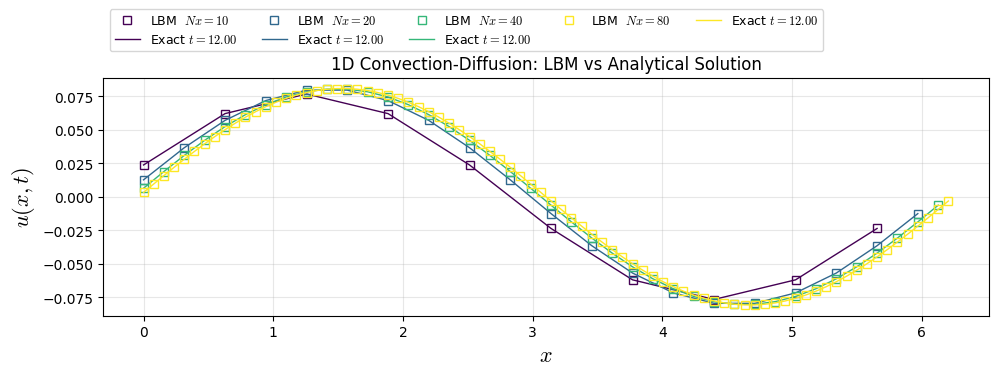

In [7]:
#****************************************Data-Analysis*********************************************
# ---------------- exact solution ----------------
def u_exact(x, t, A, k_w, phi, c, nu):
    return A * np.exp(-nu * k_w**2 * t) * np.sin(k_w * ((x+dx/2) - c*t) + phi)
u_ana = np.empty(cases, dtype=object) # array field used to same data over time
xl = np.empty(cases, dtype=object) # array field used to same data over time
for i in range(cases):
    Nx=Nx0[i]  # Numerical Length
    x  = np.linspace(0.0, L, Nx, endpoint=False,dtype="float64") # Numerical Domain
    dx = L / Nx # Grid size
    r = r0[i] # dx/dt relation
    dt = dx/r
    nt = int(np.ceil(t_end / dt))
    xl[i] = np.linspace(0.0, L, Nx0[i], endpoint=False,dtype="float64")
    u_ana[i] = np.zeros((Nx0[i]), dtype="float64")
    u_ana[i] = u_exact(xl[i], nt*dt , A, k_w, phi, c, nu)
# -----------------Plot Results --------------------
plt.figure(figsize=(10,4))
colors = plt.cm.viridis(np.linspace(0, 1, cases))
for i in range(cases):
    plt.plot(xl[i], u_cases[i], "s", color=colors[i], lw=1, label=f"LBM  $Nx={Nx0[i]:.0f}$",fillstyle='none')
    plt.plot(xl[i], u_ana[i], color=colors[i], lw=1, label=f"Exact $t={t_end:.2f}$")

plt.xlabel("$x$",fontsize=16)
plt.ylabel("$u(x,t)$",fontsize=16)
plt.title("1D Convection-Diffusion: LBM vs Analytical Solution")
plt.grid(True, alpha=0.3)
plt.legend(ncol=5,fontsize=9,loc="center left",bbox_to_anchor=(0.0, 1.2))
plt.tight_layout()
plt.show()

In [8]:
Erro= np.zeros((cases), dtype="float64")
for i in range(cases):
    Erro[i]=np.sqrt(np.sum((u_cases[i]-u_ana[i])**2))/np.sqrt(np.sum((u_ana[i])**2))
    print(f'Erro{i}=',Erro[i])
TEp=np.polyfit(np.log(Nx0), np.log(Erro), 1)
print(TEp)
print(f'ltests[i] = np.array([{1/tau1:.2f},{cs**2:.2f},{-TEp[0]:.2f},{Erro[0]},{Erro[1]},{Erro[2]},{Erro[3]}],dtype="float64")')

Erro0= 0.0007675056151644276
Erro1= 4.580188660075553e-05
Erro2= 2.84369556091393e-06
Erro3= 1.7721972578567817e-07
[-4.02508353  2.08310237]
ltests[i] = np.array([1.00,0.33,4.03,0.0007675056151644276,4.580188660075553e-05,2.84369556091393e-06,1.7721972578567817e-07],dtype="float64")


In [9]:
#------------------ List of teste cases ---------------------------
ntests=7
ltests = np.empty(ntests, dtype=object) # list [omega, cs**2, a, erro1, erro2, erro3]
ltests[0] = np.array([1.00,0.33,4.03,0.0007675056151646606,4.5801886601000255e-05,2.843695561303167e-06,1.772197264107726e-07],dtype="float64")
ltests[1] = np.array([1.33,0.33,4.00,0.0005319361354470807,3.3129765953764316e-05,2.0679546121974942e-06,1.2921092318928152e-07],dtype="float64")
ltests[2] = np.array([1.60,0.33,4.08,5.860129798788711e-05,3.189703761917948e-06,1.931515584995748e-07,1.196493783881998e-08],dtype="float64")
ltests[3] = np.array([1.78,0.33,3.99,0.0002483413735518823,1.579458417941352e-05,9.910176963429327e-07,6.199383613392777e-08],dtype="float64")
ltests[4] = np.array([0.67,0.33,4.02,0.03555687087757651,0.002131864590352776,0.00013235766481817078,8.263390671807474e-06],dtype="float64")
ltests[5] = np.array([0.40,0.33,4.05,0.5815809299211789,0.03474238662797822,0.0020727393050372516,0.00012853963043932504],dtype="float64")
ltests[6] = np.array([0.22,0.33,3.64,3.3399608313842446,0.5520470158617199,0.031960605145718385,0.0019041931043053725],dtype="float64")

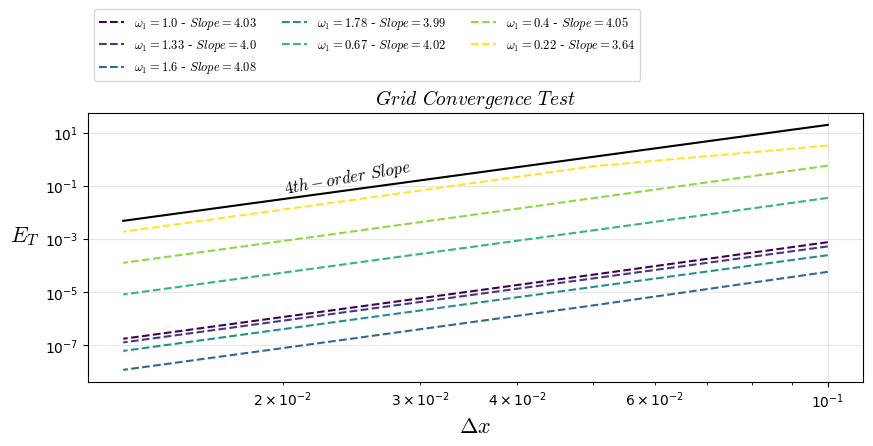

In [15]:
matplotlib.rcParams['mathtext.fontset'] = 'cm'
plt.figure(figsize=(10,3.5))
plt.title("$Grid$ $Convergence$ $Test$",fontsize=14)
colors = plt.cm.viridis(np.linspace(0, 1, ntests))
for i in range(7):
    plt.loglog(1/Nx0,ltests[i][3:],'--',color=colors[i],fillstyle='none', label=f'$\\omega_{1}={ltests[i][0]}$ - $Slope={ltests[i][2]}$')
    
plt.loglog(1/Nx0,1.*200000.0/(Nx0**4),'k-',fillstyle='none')
plt.text(0.02, 0.05, "$4th-order$ $Slope$", rotation=10,fontsize=12)
# plt.ylim(0,0.01)
plt.grid(True, alpha=0.3)
# plt.legend(loc=2,ncol=3,fontsize=8.5)
plt.legend(ncol=3,fontsize=9,loc="center left",bbox_to_anchor=(0.0, 1.25))
plt.ylabel('$E_{T}$',fontsize=16,rotation=0,horizontalalignment='right')
plt.xlabel('$\Delta x$',fontsize=16)
plt.show()